In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.datasets import load_iris

import sys
print(sys.version)



3.9.4 (default, Apr 13 2022, 21:35:52) 
[GCC 9.4.0]


In [2]:
data = load_iris(as_frame = True)
df = data.frame
df['target'] = df['target'].replace([0,1,2],data.target_names)

In [3]:
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [4]:
for name,table in df.groupby('target'):
    globals()[name+'_petal_length'] = table['petal length (cm)']
    globals()[name+'_petal_width'] = table['petal width (cm)']

/home/user/.pyenv/versions/3.9.4/lib/python3.9/site-packages/seaborn/categorical.py:1296: UserWarning: 14.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


<AxesSubplot:xlabel='target', ylabel='petal length (cm)'>

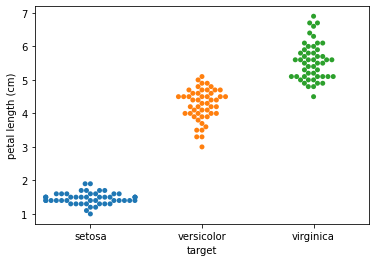

In [5]:
sns.swarmplot(x = 'target', y = 'petal length (cm)', data = df)

<AxesSubplot:xlabel='target', ylabel='petal length (cm)'>

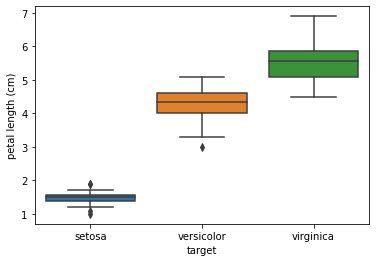

In [6]:
sns.boxplot(x = 'target', y = 'petal length (cm)', data = df)

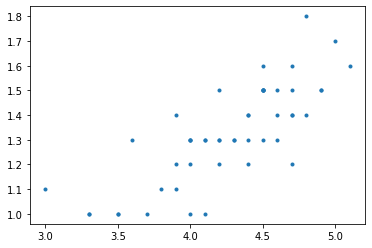

In [7]:
plt.plot(
    versicolor_petal_length,
    versicolor_petal_width,
    marker = '.',
    linestyle = 'none'
)

In [8]:
# variance
res =round(
    np.mean((versicolor_petal_length - np.mean(versicolor_petal_length)))
    ,10) 
v1 = round(
    np.mean((versicolor_petal_length - np.mean(versicolor_petal_length))**2)
    ,10)
v2 = round(
    np.var(versicolor_petal_length)
    ,10)
print(f'{res = }, {v1 = }, {v2 = }')

res = 0.0, v1 = 0.2164, v2 = 0.2164


In [10]:
# standard deviation
s1 = np.sqrt(
    np.mean(
        (versicolor_petal_length - np.mean(versicolor_petal_length))**2
    )
)
s2 = np.std(versicolor_petal_length)
print(s1, s2)

0.4651881339845203 0.4651881339845203


In [11]:
# Covariance
cv1 = np.mean(
    (versicolor_petal_length - np.mean(versicolor_petal_length)) 
    * (versicolor_petal_width - np.mean(versicolor_petal_width))
)

cv2 = np.cov(versicolor_petal_length, versicolor_petal_width, ddof = 0)

print(cv1, cv2)

0.07164 [[0.2164   0.07164 ]
 [0.07164  0.038324]]


In [13]:
# Degrees of freedom: n - ddof
# 0 = population; 1 = sample
p1 = versicolor_petal_length - np.mean(versicolor_petal_length)
p2 = versicolor_petal_width - np.mean(versicolor_petal_width)
n = 50

(p1*p1).sum()/n, (p1*p2).sum()/n, (p2*p1).sum()/n, (p2*p2).sum()/n

(0.21640000000000004, 0.07164, 0.07164, 0.038324)

In [14]:
# Pearson correlation (ddof = 1)
ddof = 0
cov = np.cov(versicolor_petal_length, versicolor_petal_width, ddof = ddof)[0,1]

std_l = np.std(versicolor_petal_length, ddof = ddof)
std_w = np.std(versicolor_petal_width, ddof = ddof)

pearson_corr_rawish = cov/(std_l*std_w)

pearson_corr_f = np.corrcoef(versicolor_petal_length, versicolor_petal_width)

print(cov, std_l, std_w, pearson_corr_rawish)
print(pearson_corr_rawish, pearson_corr_f)


0.07164 0.4651881339845203 0.19576516544063705 0.7866680885228169
0.7866680885228169 [[1.         0.78666809]
 [0.78666809 1.        ]]


In [15]:
# calculating pearson raw

cov = np.sum(
    (versicolor_petal_length - np.mean(versicolor_petal_length))
     * (versicolor_petal_width - np.mean(versicolor_petal_width))
)/len(versicolor_petal_length)


var_l = np.sum(
    (versicolor_petal_length - np.mean(versicolor_petal_length))**2
)/len(versicolor_petal_length)

var_w = np.sum(
    (versicolor_petal_width - np.mean(versicolor_petal_width))**2
)/len(versicolor_petal_length)

std_l = var_l**0.5
std_w = var_w**0.5

pearson = cov/(std_l*std_w)

cov, std_l, std_w, pearson

(0.07164, 0.4651881339845203, 0.19576516544063705, 0.7866680885228169)

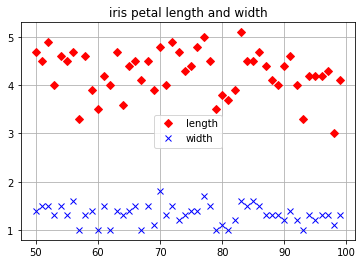

In [16]:
plt.plot((versicolor_petal_length), marker = 'D', linestyle = 'none', color = 'r', label = 'length')
plt.plot((versicolor_petal_width), marker = 'x', linestyle = 'none', color = 'b', label = 'width')
plt.title('iris petal length and width')
plt.legend(loc = 10)
plt.grid()

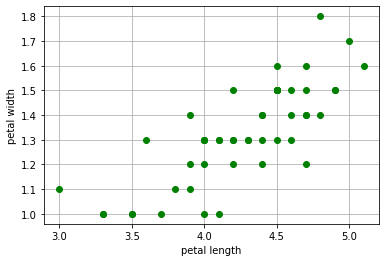

In [17]:
plt.plot(versicolor_petal_length, versicolor_petal_width, marker = 'o', linestyle = 'none', color = 'g')
plt.xlabel('petal length')
plt.ylabel('petal width')
plt.grid()

In [18]:
a = np.arange(1,100)

b = np.arange(99,0,-1)

In [19]:
np.cov(a,a), np.cov(a,b)

(array([[825., 825.],
        [825., 825.]]),
 array([[ 825., -825.],
        [-825.,  825.]]))

In [20]:
np.var(a), np.var(b)

(816.6666666666666, 816.6666666666666)

In [21]:
np.corrcoef(a,a)[1,1], np.corrcoef(a,b)[1,1]

(0.9999999999999999, 0.9999999999999999)

In [22]:
for x in range(10,101, 10):
    l = np.arange(1,x,1)
    ll = np.arange(x-1, 0, -1)
    print(
        x, 
        round(np.var(l, ddof = 0),2),
#         round(np.std(l, ddof = 0),2),
        round(np.cov(l, l, ddof = 0)[0,1],2),
        round(np.cov(l, ll, ddof = 0)[0,1],2),
        np.corrcoef(l, l)[0,1],
        np.corrcoef(l, ll)[0,1]
    )

10 6.67 6.67 -6.67 1.0 -1.0
20 30.0 30.0 -30.0 1.0 -1.0
30 70.0 70.0 -70.0 0.9999999999999998 -0.9999999999999998
40 126.67 126.67 -126.67 1.0 -1.0
50 200.0 200.0 -200.0 0.9999999999999999 -0.9999999999999999
60 290.0 290.0 -290.0 1.0 -1.0
70 396.67 396.67 -396.67 1.0 -1.0
80 520.0 520.0 -520.0 1.0 -1.0
90 660.0 660.0 -660.0 1.0 -1.0
100 816.67 816.67 -816.67 0.9999999999999999 -0.9999999999999999


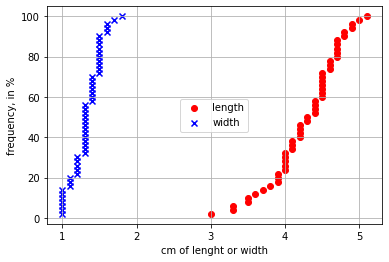

In [23]:
# Empirical Cumulative Distribution Function

def ecdf(data):
    l = len(data)
    x = np.sort(data)
    y = np.arange(1, l+1)/l*100
    return x,y

ecdf_lx, ecdf_ly = ecdf(versicolor_petal_length)
ecdf_wx, ecdf_wy = ecdf(versicolor_petal_width)

plt.scatter(ecdf_lx, ecdf_ly, marker = 'o', color = 'r', label = 'length')
plt.scatter(ecdf_wx, ecdf_wy, marker = 'x', color = 'b',  label = 'width')

plt.ylabel('frequency, in %')
plt.xlabel('cm of lenght or width')

plt.legend(loc = 10)
plt.grid()


---

In [24]:
# Bernoulli Trials
np.random.seed(42)
def bernoulli_trial(n,p):
    r = 0
    
    for x in range(n):
        rand = np.random.random()
        if rand < p:
            r+=1
    return r

bernoulli_trial(100, 0.8), np.random.binomial(100,0.8)
# np.random.binomial(100,0.8),bernoulli_trial(100, 0.8)
# bernoulli_trial(100, 0.8), bernoulli_trial(100, 0.8)


(82, 87)

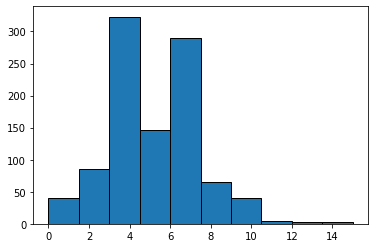

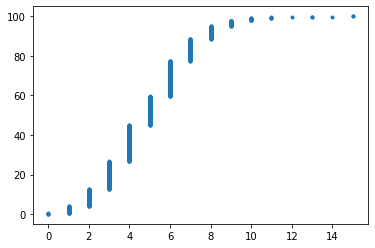

In [25]:
# bernoulli trials 2
n = 1000
p = 0.05

np.random.seed(42)

l = np.empty(n)

for x in range(n):
    l[x] = bernoulli_trial(100, p)
    
plt.hist(l, ec = 'k')
plt.show()

x,y = ecdf(l)
plt.plot(x,y, linestyle = 'none', marker = '.')

[5 5 4 ... 6 1 2]


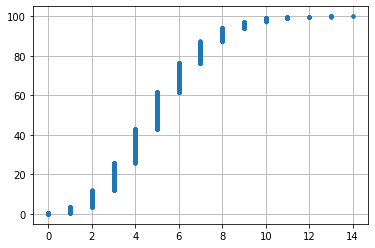

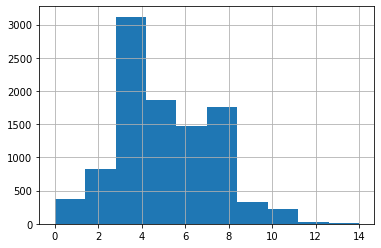

In [26]:
# bernoulli trials: binomial distribution
n_defaults = np.random.binomial(n = 100, p = 0.05, size = 10_000)
print(n_defaults)
x,y = ecdf(n_defaults)
plt.plot(x,y, marker = '.', linestyle = 'none')
plt.grid()
plt.show()
plt.hist(n_defaults)
plt.grid()
plt.show()

(array([0.0062, 0.0307, 0.0819, 0.1409, 0.171 , 0.1861, 0.147 , 0.1087,
        0.0678, 0.033 , 0.0168, 0.0062, 0.0021, 0.0012, 0.0004]),
 array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5,
        10.5, 11.5, 12.5, 13.5, 14.5]),
 <BarContainer object of 15 artists>)

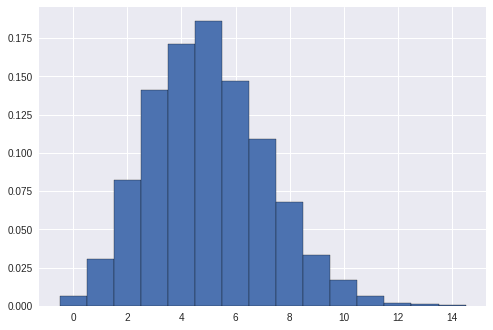

In [27]:
# Probability Mass Function (PMF)

bins = np.arange(0, max(n_defaults)+2) - 0.5
plt.style.use('seaborn')
plt.hist(n_defaults,bins = bins, density = True,  ec='black')


---

0.0 10.004428
[-0.5  0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5
 13.5 14.5 15.5 16.5 17.5 18.5 19.5 20.5]


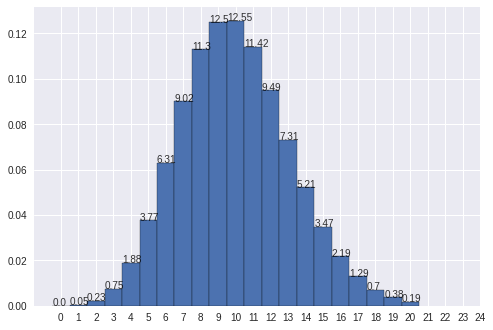

In [28]:
# Poisson distribution: "fake" poisson
np.random.seed(42)
n = int(1e10)
p = 10/n
queue = np.random.binomial(n = n, p = p, size = 1_000_000)
print(round(p*100,2), np.mean(queue))
bins = np.arange(0, 22)-0.5
print(bins)
plt.hist(queue, bins = bins, density = True, ec = 'black')
prob,bins = np.histogram(queue, bins = bins, density = True)
plt.xticks(range(0,25))
for i in range(len(prob)):
    plt.text(bins[i],prob[i], round(prob[i]*100,2), color = 'black',  alpha = 0.8)

(array([1.00135182e-05, 5.10689431e-04, 2.27306864e-03, 7.56020628e-03,
       1.93461173e-02, 3.77609773e-02, 6.38361788e-02, 9.09928403e-02,
       1.12802283e-01, 1.27301858e-01, 1.24357883e-01, 1.14334351e-01,
       9.55990587e-02, 7.27482101e-02, 5.10389025e-02, 3.42762730e-02,
       2.07480098e-02, 1.22665599e-02, 6.94938167e-03, 3.50473139e-03,
       1.78240625e-03]), array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5,
       10.5, 11.5, 12.5, 13.5, 14.5, 15.5, 16.5, 17.5, 18.5, 19.5, 20.5]), <BarContainer object of 21 artists>)


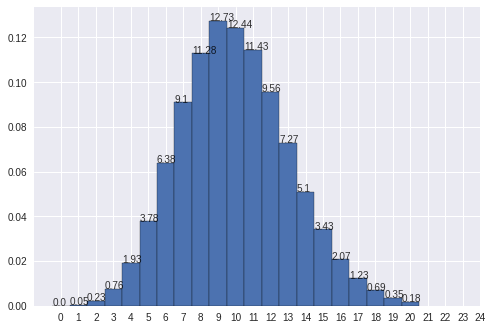

In [29]:
# "true" poisson
lala = np.random.poisson(10, size = 100000)

hist = plt.hist(lala, bins = bins, density = True, ec = 'black')
print(hist)
freq,bins = hist[0], hist[1]
plt.xticks(range(0,25))
for i in range(len(freq)):
    plt.text(bins[i],freq[i], round(freq[i]*100,2), color = 'black',  alpha = 0.8)

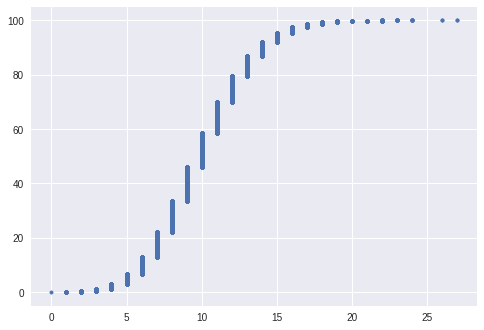

In [30]:
x,y = ecdf(lala)
plt.scatter(x,y, marker = '.')

(array([1.000e-04, 6.000e-04, 2.600e-03, 7.400e-03, 1.790e-02, 3.350e-02,
        6.400e-02, 9.390e-02, 1.155e-01, 1.249e-01, 1.302e-01, 1.123e-01,
        9.380e-02, 6.920e-02, 4.990e-02, 3.350e-02, 2.170e-02, 1.320e-02,
        7.900e-03, 3.500e-03, 1.500e-03, 1.900e-03, 6.000e-04, 3.000e-04,
        0.000e+00, 1.000e-04]),
 array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5,
        10.5, 11.5, 12.5, 13.5, 14.5, 15.5, 16.5, 17.5, 18.5, 19.5, 20.5,
        21.5, 22.5, 23.5, 24.5, 25.5]),
 <BarContainer object of 26 artists>)

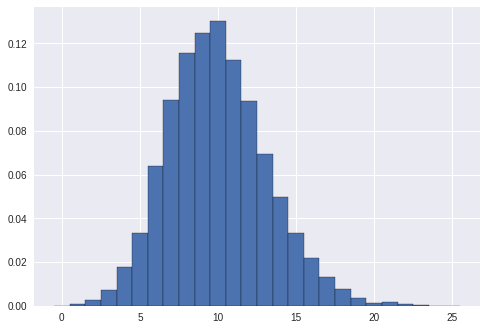

In [31]:
yo = np.random.poisson(10,10000) 
bins = np.arange(0, 27)-0.5

plt.hist(yo, bins = bins, density = True, ec = 'k')

In [32]:
[x for x in dir() if 'pet' in x]

['setosa_petal_length',
 'setosa_petal_width',
 'versicolor_petal_length',
 'versicolor_petal_width',
 'virginica_petal_length',
 'virginica_petal_width']

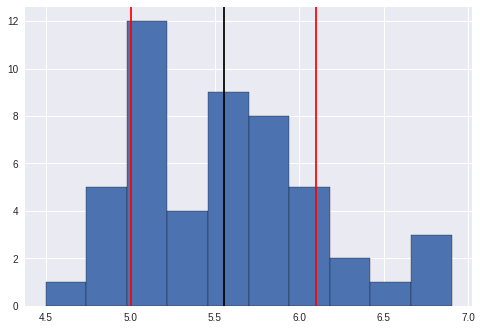

In [33]:
plt.hist(virginica_petal_length, ec = 'k')
mean_l = np.mean(virginica_petal_length)
var_l = np.mean((virginica_petal_length - mean_l)**2)
std_l = np.sqrt(var_l)
plt.axvline(mean_l + std_l, color = 'red')
plt.axvline(mean_l - std_l, color = 'red')
plt.axvline(mean_l, color = 'k')

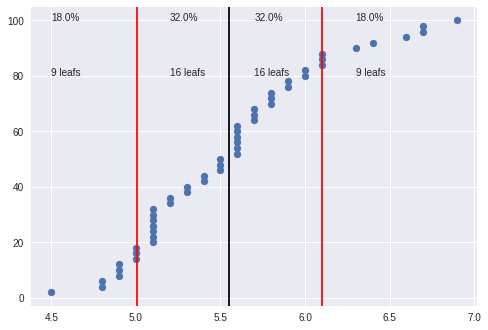

In [34]:
# Number of leaves per std 

xvl,yvl = ecdf(virginica_petal_length)
plt.scatter(xvl,yvl)
li = mean_l - std_l
ui = mean_l + std_l
plt.axvline(mean_l + std_l, color = 'red')
plt.axvline(mean_l - std_l, color = 'red')
plt.axvline(mean_l, color = 'k')

x1 = np.sum(virginica_petal_length < (li))
x4 = np.sum(virginica_petal_length > (ui))
x2 = np.sum((virginica_petal_length < mean_l) & (virginica_petal_length > li))
x3 = np.sum((virginica_petal_length > mean_l) & (virginica_petal_length < ui))
for x,y in zip([4.5,5.2,5.7,6.3],[x1,x2,x3,x4]):
    plt.text(x,100,str(y/50*100) + '%')
    plt.text(x,80,str(y) + ' leafs')


Text(0.5, 1.0, 'blue: normal dist; green: real data')

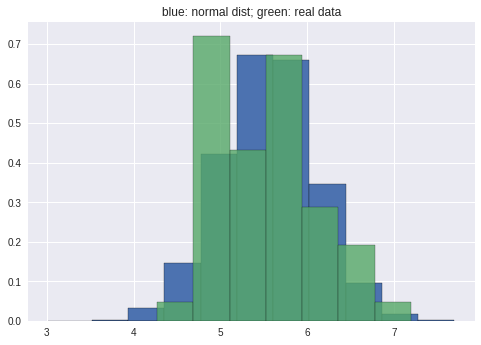

In [35]:
# Normal distribution
lala = np.random.normal(loc = mean_l, scale = std_l, size = 10000)

hist1 = plt.hist(lala, ec = 'k', density = True)
hist2 = plt.hist(virginica_petal_length, ec = 'k', bins = hist1[1] - 0.5, alpha = 0.8, density = True)

plt.title('blue: normal dist; green: real data')


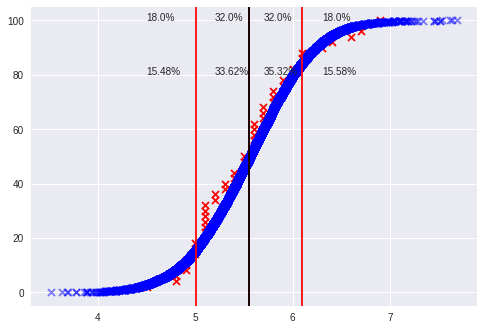

In [36]:
xl, yl = ecdf(lala)
plt.scatter(xvl, yvl, color = 'red', marker = 'x')
plt.scatter(xl, yl, color = 'blue', marker = 'x', alpha = 0.5)

plt.axvline(np.mean(lala), color = 'r')

plt.axvline(mean_l + std_l, color = 'red')
plt.axvline(mean_l - std_l, color = 'red')
plt.axvline(mean_l, color = 'k')

lx1 = np.sum(lala < (li))
lx4 = np.sum(lala > (ui))
lx2 = np.sum((lala < mean_l) & (lala > li))
lx3 = np.sum((lala > mean_l) & (lala < ui))

for x,y,z in zip([4.5,5.2,5.7,6.3],[x1,x2,x3,x4], [lx1,lx2,lx3,lx4]):
    plt.text(x,100,str(y/50*100) + '%')    
    plt.text(x, 80, str(z/100) + '%')
    


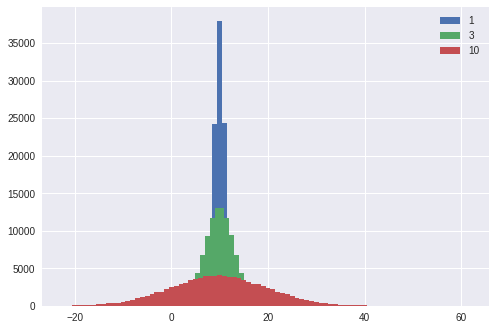

In [37]:
# normal distribution: std and ECDF
lala1 = np.random.normal(loc = 10, scale = 1, size = 100_000)
lala3 = np.random.normal(loc = 10, scale = 3, size = 100_000)
lala10 = np.random.normal(loc = 10, scale = 10, size = 100_000)

bins = np.arange(-22,62)

plt.hist(lala1, label = 1, bins = bins - 0.5)
plt.hist(lala3, label = 3, bins = bins)
plt.hist(lala10, label = 10, bins = bins + 0.5)
plt.legend()


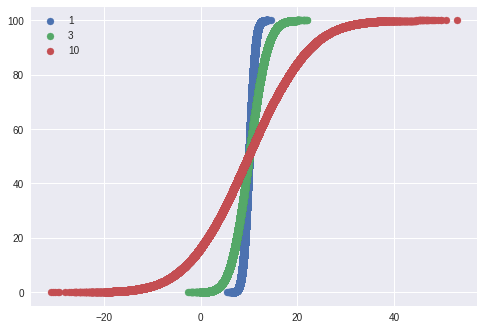

In [38]:
x1,y1 = ecdf(lala1)
x3,y3 = ecdf(lala3)
x10,y10 = ecdf(lala10)

plt.scatter(x1,y1, label = 1)
plt.scatter(x3,y3, label = 3)
plt.scatter(x10,y10, label = 10)
plt.legend()

In [39]:
x = np.random.poisson(lam = 10, size = 100_000)
np.mean(x), np.std(x)

(10.00067, 3.170976119604183)

0.04999997133329417 0.0674712728574604
99.99994266658834


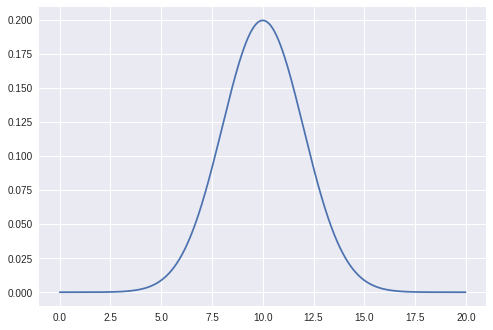

In [40]:
def normal(x, mean, std):
    p1 = 1/(std*np.sqrt(2*np.pi))
    p2 = np.e
    p3 = -(x-mean)**2/(2*(std**2))
    return p1*(p2**p3)
l1 = []
l2 = []
for x in np.arange(0,20,0.01):
    value = normal(x,mean = 10, std = 2)
    
    l1.append(x)
    l2.append(value)
print(np.mean(l2), np.std(l2))
print(np.sum(l2))
plt.plot(l1,l2)


In [41]:
# normal distribution: belmont winners horse races
import importlib 

import lxml

df_races = pd.read_html('https://en.wikipedia.org/wiki/Belmont_Stakes')[1]

df_races['time'] =  '00:' + df_races['Time*']
df_races = df_races.dropna(subset = ['time'])
df_races['time'] = pd.to_timedelta(df_races['time'], errors = 'coerce').dt.total_seconds()

df_races = df_races.query('time > 140 & time < 150')
print(df_races.shape)
df_races['time']

(79, 10)


0      147.11
2      148.30
3      148.18
5      148.51
6      146.65
        ...  
120    141.00
121    141.25
122    143.00
124    143.25
125    144.50
Name: time, Length: 79, dtype: float64

147.47379746835443 2.4453620694618525
147.46443444328912 2.4392812071682592


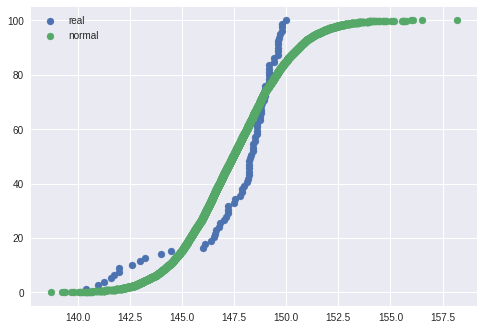

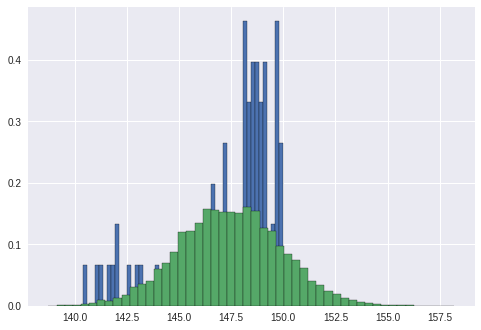

In [42]:
mu, sigma = df_races['time'].apply(['mean','std'])
print(mu, sigma)
samples = np.random.normal(loc = mu, scale = sigma, size = 10_000)
mu, sigma = np.mean(samples), np.std(samples)
print(mu, sigma)
xr, yr = ecdf(df_races['time'])
xf, yf = ecdf(samples)

plt.scatter(xr, yr, label = 'real')
plt.scatter(xf, yf, label = 'normal')
plt.legend()
plt.show()


plt.hist(df_races['time'], density = True, bins = 50, ec = 'k')
plt.hist(samples, density = True, bins = 50, ec = 'k')
plt.show()

In [43]:
df_races['time'].describe()

count     79.000000
mean     147.473797
std        2.445362
min      140.400000
25%      146.910000
50%      148.300000
75%      149.000000
max      149.970000
Name: time, dtype: float64

In [44]:
'00:'+races[0]

NameError: name 'races' is not defined

In [ ]:
def expon(x, mean):
    result = 1-np.e**(-x/mean)
    return result 
expon(1,20), expon(2,20) - expon(1,20)

In [ ]:
x = np.arange(250)
y = np.array([expon(i,20) for i in x])
y2 = 1-y
plt.plot(x,y)
plt.plot(x,y2)
plt.ylabel('probabilidade de chegar alguém')
plt.xlabel('tempo, em minutos')

In [ ]:

xx = np.sort(np.random.exponential(20, size = 20000))[::-1]
x,y = ecdf(xx)
plt.plot(x,y)


In [ ]:
def exp2(x, mean):
    result = (1/mean)**

In [ ]:
def successive_poisson(tau1, tau2, size=1):
    """Compute time for arrival of 2 successive Poisson processes."""
    # Draw samples out of first exponential distribution: t1
    t1 = np.random.exponential(tau1, size)

    # Draw samples out of second exponential distribution: t2
    t2 = np.random.exponential(tau2, size)

    return t1 + t2

In [ ]:
# Draw samples of waiting times: waiting_times
waiting_times = successive_poisson(764, 715, 100_000)

# Make the histogram
plt.hist(waiting_times, bins = 100, density = True)


# Label axes
plt.xlabel('')
plt.ylabel('')

# Show the plot
plt.show()
x,y = ecdf(waiting_times)
plt.scatter(x,y)
plt.show()

In [ ]:
np.mean(waiting_times)

In [ ]:
x = np.random.poisson(lam = 6, size = 10_000)
x[:3], np.mean(x), np.std(x)

In [ ]:
x = np.random.normal(loc = 6, size = 10_000)
x[:3], np.mean(x), np.std(x)

In [ ]:
np.percentile(virginica_petal_length, [50]), np.median(virginica_petal_length)

In [ ]:
[x for x in dir() if 'petal' in x]

In [ ]:
# Probability density function

# 1. np.random.exponential(scale, size):
# returns a random number from a exponential curve, with mean and std = 10
# [1,1,2,2,3,10,4,4,1,1,...]
# most frequent are the smallest ones - higher chance of happening at the beginning
# least frequent are the bigger ones - lower chance of happening at the end 
# -> (chance of happening * chance of not happening before)
np.random.seed(42)
lala = np.sort(np.random.exponential(scale = 10, size = 10000))
print(np.mean(lala), np.std(lala), np.min(lala), np.max(lala))

xnp, ynp = ecdf(lala)
plt.plot(xnp,ynp)
plt.title('x: number from exp curve\n y: frequency, in pct')

In [ ]:
# cool formula (not taught on datacamp): F(x, mean) = 1 - np.exp(-x/mean)
# for each possible x, returns the probability of seeing x

def f1(x, mean):
    return 1 - np.exp(-x/mean)

xf = np.arange(0,100,0.1)
yf = [f1(i, 10) for i in x]

plt.plot(xf,yf)

In [ ]:
# final proof

plt.plot(xf, yf, label = 'formula: 1-e**(-x/u)')
plt.plot(xnp, ynp, label = 'np.random.exponential')
plt.legend()